# Image Compression using the SVD

In this notebook you will experiment with compression images by constructing a low rank approximation to the matrix of a bitmap image.

In [2]:
import numpy as np
import matplotlib.pyplot as plt


First we use PIL to load an image and numpy to convert it to a 2D array.

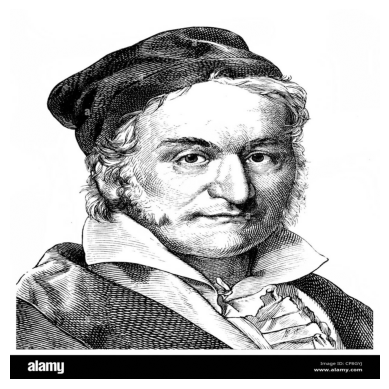

In [3]:
from PIL import Image
import numpy as np

# Open the image
img = Image.open("gauss.jpg")
img = img.resize((1024,1024))
# Convert the image to grayscale
img_gray = img.convert("L")

# Convert the image to a NumPy array
img_matrix = np.array(img_gray)
# Display the matrix
plt.imshow(img_matrix, cmap="gray", aspect=1.0)
plt.axis("off")  # Hide axes for a cleaner look
plt.show()

## Plotting the singular values

The key to image compression is factoring the image matrix $A$ into $A = U S V^T$ (we use $S$ instead of $\Sigma$). Remember $S$ is a diagonal matrix of singular values, sorted from greatest to least. Plotting the singular values lets us find an approximate break-point between "big" and "small" ones

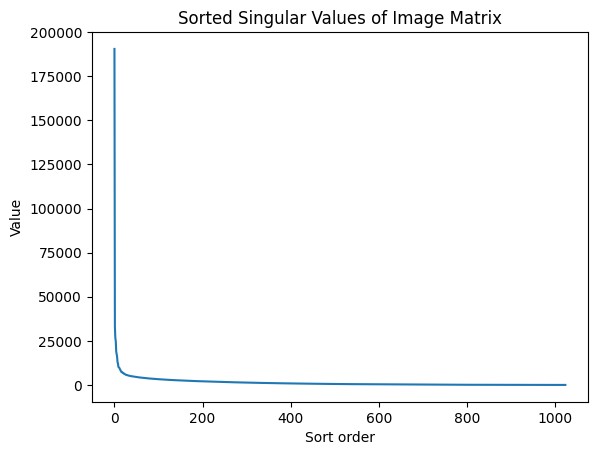

In [4]:
U, S, VT = np.linalg.svd(img_matrix)
plt.plot(S);
plt.title("Sorted Singular Values of Image Matrix")
plt.xlabel("Sort order")
plt.ylabel("Value");

From the above graph, there are 1024 singular values and they start around 200,000. But they quickly plummet to near zero. Let's see what the first 10 look like.

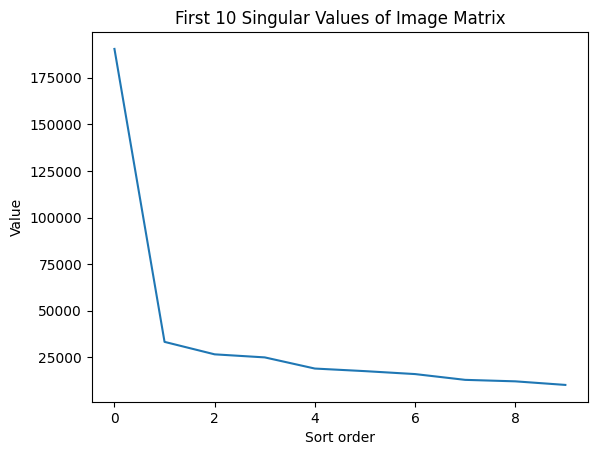

In [ ]:
plt.plot(S[:10])
plt.title("First 10 Singular Values of Image Matrix")
plt.xlabel("Sort order")
plt.ylabel("Value");

## Image Compression and Reconstruction

The trick to image compression is to zero out some of the 1,024 singular values. Say we keep 25. This is a compression because then we can keep only 25 columns of $U$ and $V$. The matrix product will still be 1,024 x 1,024, but in memory we're storing 1,024 x 25 for each of the two big matrices. A huge win!

In [14]:
## Make a new copy of S and zero out several of the singular values

S2 = S.copy()
S2[25:]= 0

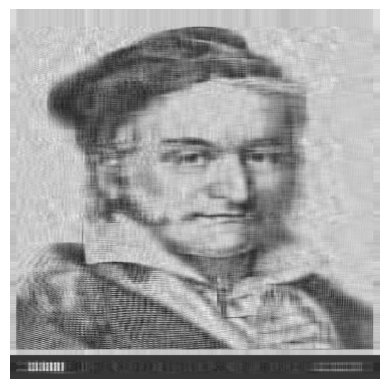

In [16]:
## Reconstruct the image and plot by multiplying

new_image = U@(np.diag(S2)@VT)

plt.imshow(new_image, cmap="gray")
plt.axis("off")  # Hide axes for a cleaner look
plt.show()

Now this is obviously a lossy compression, but this is the result of throwing away 98% of the original image data! If you keep more singular values you can trade off compression size against quality.

## Your Assignment

### Plot the reconstruction error

If the original matrix image is $A$ and the reconstructed image is matrix $B$, you can numerically calculate the error between the two matrices. The RMSE (root mean squared error) could be used here, and when applied to a matrix is called the **Frobenius Norm**. It can be computed in numpy as `norm = np.linalg.norm(A-B)`

Make a graph of error (y-axis) vs. number of singular values in the compressed matrix (x-axis) for the above image. The error should start off large and drop to 0 eventually.

In [17]:
## your code

### The best compression

Experiment with different matrix ranks using the above graphs and decide which size you think personally is the best trade off of size vs quality (obviously there is no right answer). Determine the efficiency of your compression (size of original matrix vs. size of SVD). Which matrix rank did you choose and why? Show the reconstruction here.

In [18]:
## image

How much space did you save? Compute the exact value here (original $A$ vs. $U,S,V$ combined)

In [9]:
## compute the efficiency here

## Go Fish

Find your own image online and compress it. To mirror the above procedure you'll want to find a grayscale image, or convert it to grayscale (easy to do with PIL). If you're up for a slight challenge, keep the image in RGB, compress each channel separately and recombine. Discuss your process and results below, along with all your code.